# SlumberWell — Phase 1: ML Experimentation
**Sleep stage classification with traditional machine learning (Sleep-EDF Expanded, Sleep Cassette)**

Follows *SlumberWell Technical and Functional Specification v1.0*. Pipeline:

1. Load PSG + hypnogram EDFs → band-pass → 30 s epochs → labels (W, N1, N2, N3, REM)
2. 16 handcrafted features per epoch (statistical, band power, relative power, spectral entropy)
3. **Subject-wise** train / validation / test split (both nights of a subject stay together)
4. Compare Random Forest, Extra Trees, XGBoost, SVM, HistGradientBoosting against a majority baseline
5. Tune strongest candidates, select by **validation macro F1**, evaluate **once** on test
6. Export artifacts for the FastAPI backend

Runs on Colab, Kaggle, or local Jupyter. Start with `N_SUBJECTS` small to validate end to end, then scale up (spec §4.6).

## 0. Setup

In [2]:
%pip install -q mne xgboost scikit-learn scipy pandas matplotlib seaborn joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.2.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import json, time, platform, warnings, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import mne, sklearn, scipy, xgboost

from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, f1_score, recall_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)
from xgboost import XGBClassifier

mne.set_log_level("ERROR")
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")

## 1. Configuration
Everything that affects results lives here. `SEED` drives the split and every model.

In [4]:
SEED = 42
random.seed(SEED); np.random.seed(SEED)

# --- data -------------------------------------------------------------------
DATA_SOURCE = "download"   # "download" -> fetch only the chosen subjects from PhysioNet (recommended to start)
                           # "wget" -> use the full-dataset download in section 2 and read from WGET_DIR
N_SUBJECTS  = 10           # staged usage (spec 4.6): start small (5-10; ~50 MB per recording), then scale up to 78
WGET_DIR    = Path("physionet.org/files/sleep-edfx/1.0.0/sleep-cassette")

# --- paths ------------------------------------------------------------------
ARTIFACT_DIR = Path("artifacts");  ARTIFACT_DIR.mkdir(exist_ok=True)
CACHE_DIR    = Path("cache");      CACHE_DIR.mkdir(exist_ok=True)

# --- experiment switches ----------------------------------------------------
TRIM_WAKE        = True    # spec step 7: limit wake around sleep (validate effect below)
WAKE_MARGIN_MIN  = 30
APPLY_QUALITY    = True    # spec step 8: drop flat / extreme-amplitude epochs
REFIT_TRAIN_VAL  = True    # spec 7.5 step 4
N_TUNING_TRIALS  = 8       # random draws per tuned model from the spec 7.4 grids
TUNE_TOP_K       = 2       # tune the K best default models (RF and XGBoost always included)
DOWNLOAD_RETRIES = 5      # per-subject retries with exponential backoff (PhysioNet can time out)
SVM_MAX_TRAIN    = 20000   # SVC is O(n^2); random subsample of train for SVM only

## 2. Shared core module
Preprocessing, epoching, labelling and feature code is written to `slumberwell_core.py` and **imported**, so the
backend can use the exact same file (spec §3.3, no training/serving skew). Copy this file into the backend package.

In [5]:
%%writefile slumberwell_core.py
"""SlumberWell shared core: preprocessing, epoching, labelling and feature extraction.

Imported by BOTH the training notebook and the FastAPI backend so that training
and inference produce identical features (no training/serving skew).
"""
from __future__ import annotations

import re
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.integrate import trapezoid
from scipy.signal import butter, resample_poly, sosfiltfilt, welch

# --------------------------------------------------------------------------- #
# Labels (spec section 4.4)
# --------------------------------------------------------------------------- #
STAGE_NAMES = ["W", "N1", "N2", "N3", "REM"]
LABEL_TO_INT = {name: i for i, name in enumerate(STAGE_NAMES)}
INT_TO_LABEL = {i: name for name, i in LABEL_TO_INT.items()}

# Hypnogram annotation text -> SlumberWell stage. Movement / unscored are absent
# on purpose: they are excluded, never treated as a sleep stage.
ANNOTATION_MAP = {
    "Sleep stage W": "W",
    "Sleep stage 1": "N1",
    "Sleep stage 2": "N2",
    "Sleep stage 3": "N3",
    "Sleep stage 4": "N3",   # stages 3 + 4 merged (AASM convention)
    "Sleep stage R": "REM",
}

DEFAULT_CONFIG = {
    "channels": ["EEG Fpz-Cz"],
    "sampling_rate_hz": 100,
    "bandpass_hz": [0.3, 35.0],
    "filter_order": 4,
    "epoch_length_sec": 30,
    "welch": {"window_sec": 4, "overlap": 0.5},
    "bands_hz": {"delta": [0.5, 4.0], "theta": [4.0, 8.0],
                 "alpha": [8.0, 13.0], "beta": [13.0, 30.0]},
    "total_power_range_hz": [0.5, 30.0],
    "min_duration_epochs": 10,
    # training-only parameters (filled in by the notebook, stored for the record)
    "wake_margin_min": 30,
    "quality": {"flat_std_uv": 0.1, "max_abs_uv": None},
}


# --------------------------------------------------------------------------- #
# File-name helpers (spec section 4.2)
# --------------------------------------------------------------------------- #
def parse_sc_name(path) -> dict:
    """SC4ssNE0-PSG.edf -> subject number ss and night N."""
    name = Path(path).name
    m = re.match(r"SC4(\d{2})(\d)", name)
    if not m:
        raise ValueError(f"Not a Sleep Cassette file name: {name}")
    return {"subject": int(m.group(1)), "night": int(m.group(2))}


def find_hypnogram(psg_path) -> Path | None:
    """SC4001E0-PSG.edf -> SC4001E?-Hypnogram.edf in the same folder."""
    psg_path = Path(psg_path)
    prefix = psg_path.name.split("-")[0][:7]          # e.g. SC4001E
    hits = sorted(psg_path.parent.glob(f"{prefix}*-Hypnogram.edf"))
    return hits[0] if hits else None


# --------------------------------------------------------------------------- #
# Signal loading and preprocessing (spec section 5, steps 1, 3, 4, 5)
# --------------------------------------------------------------------------- #
def read_edf(path, channels, verbose=False):
    """Read an EDF with MNE and return (signals_uV [n_ch, n_samples], sfreq, raw)."""
    import mne  # imported lazily so the module can be imported without MNE
    raw = mne.io.read_raw_edf(str(path), preload=False, verbose=verbose)
    missing = [c for c in channels if c not in raw.ch_names]
    if missing:
        raise KeyError(f"Channel(s) {missing} not found. Available channels: {raw.ch_names}")
    raw.pick(channels)
    raw.load_data(verbose=verbose)
    return raw.get_data() * 1e6, raw.info["sfreq"], raw      # volts -> microvolts


def resample_to(x, sfreq, target_sfreq):
    """Resample along the last axis to target_sfreq (no-op if already equal)."""
    if abs(sfreq - target_sfreq) < 1e-6:
        return x
    from fractions import Fraction
    frac = Fraction(target_sfreq / sfreq).limit_denominator(1000)
    return resample_poly(x, frac.numerator, frac.denominator, axis=-1)


def bandpass(x, fs, low, high, order=4):
    sos = butter(order, [low, high], btype="band", fs=fs, output="sos")
    return sosfiltfilt(sos, x, axis=-1)


def make_epochs(x, fs, epoch_len_sec=30):
    """Cut [n_ch, n_samples] into non-overlapping epochs [n_epochs, n_ch, n_per_epoch].
    An incomplete final epoch is discarded (FR-03)."""
    n = int(round(epoch_len_sec * fs))
    n_epochs = x.shape[-1] // n
    x = x[..., : n_epochs * n]
    return x.reshape(x.shape[0], n_epochs, n).transpose(1, 0, 2)


def preprocess_signal(path, cfg):
    """EDF path -> epochs [n_epochs, n_ch, samples] in uV (resampled, band-passed)."""
    x, sfreq, raw = read_edf(path, cfg["channels"])
    fs = cfg["sampling_rate_hz"]
    x = resample_to(x, sfreq, fs)
    x = bandpass(x, fs, *cfg["bandpass_hz"], order=cfg.get("filter_order", 4))
    return make_epochs(x, fs, cfg["epoch_length_sec"]), raw


# --------------------------------------------------------------------------- #
# Labels from a hypnogram (spec section 5, step 6)
# --------------------------------------------------------------------------- #
def epoch_labels_from_annotations(onsets, durations, descriptions, n_epochs, epoch_len=30):
    """Return int array [n_epochs]; -1 = excluded (movement, unscored, uncovered).
    An epoch is labelled only if it lies entirely inside one mapped annotation."""
    labels = np.full(n_epochs, -1, dtype=int)
    eps = 1e-6
    for onset, dur, desc in zip(onsets, durations, descriptions):
        stage = ANNOTATION_MAP.get(str(desc).strip())
        if stage is None:
            continue
        first = int(np.ceil((onset - eps) / epoch_len))
        last = int(np.floor((onset + dur + eps) / epoch_len))   # exclusive
        first, last = max(first, 0), min(last, n_epochs)
        if last > first:
            labels[first:last] = LABEL_TO_INT[stage]
    return labels


def read_hypnogram(hyp_path, raw):
    """Read hypnogram annotations; return onsets relative to the PSG start."""
    import mne
    ann = mne.read_annotations(str(hyp_path))
    onsets = np.asarray(ann.onset, dtype=float)
    if ann.orig_time is not None and raw.info["meas_date"] is not None:
        onsets = onsets + (ann.orig_time - raw.info["meas_date"]).total_seconds()
    return onsets, np.asarray(ann.duration, dtype=float), list(ann.description)


def trim_wake_mask(labels, margin_epochs):
    """Keep wake only within margin_epochs before the first / after the last sleep epoch."""
    sleep_idx = np.where(labels > LABEL_TO_INT["W"])[0]
    keep = np.zeros(len(labels), dtype=bool)
    if len(sleep_idx) == 0:
        return keep
    lo = max(sleep_idx[0] - margin_epochs, 0)
    hi = min(sleep_idx[-1] + margin_epochs + 1, len(labels))
    keep[lo:hi] = True
    return keep


# --------------------------------------------------------------------------- #
# Feature engineering (spec section 6): 16 features per channel
# --------------------------------------------------------------------------- #
BASE_FEATURES = (
    ["mean", "std", "var", "rms", "min", "max", "range"]
    + ["delta_power", "theta_power", "alpha_power", "beta_power"]
    + ["rel_delta", "rel_theta", "rel_alpha", "rel_beta"]
    + ["spectral_entropy"]
)


def feature_names(cfg) -> list[str]:
    chs = cfg["channels"]
    if len(chs) == 1:
        return list(BASE_FEATURES)
    safe = [c.replace(" ", "_").replace("-", "_") for c in chs]
    return [f"{c}__{f}" for c in safe for f in BASE_FEATURES]


def _channel_features(ep, cfg):
    """ep: [n_epochs, samples] -> dict of feature arrays [n_epochs]."""
    fs = cfg["sampling_rate_hz"]
    f = {}
    f["mean"] = ep.mean(axis=1)
    f["std"] = ep.std(axis=1)
    f["var"] = ep.var(axis=1)
    f["rms"] = np.sqrt((ep ** 2).mean(axis=1))
    f["min"] = ep.min(axis=1)
    f["max"] = ep.max(axis=1)
    f["range"] = f["max"] - f["min"]

    nperseg = int(cfg["welch"]["window_sec"] * fs)
    noverlap = int(nperseg * cfg["welch"]["overlap"])
    freqs, psd = welch(ep, fs=fs, nperseg=nperseg, noverlap=noverlap, axis=-1)

    def band_power(lo, hi):
        m = (freqs >= lo) & (freqs <= hi)
        return trapezoid(psd[:, m], freqs[m], axis=1)

    bands = {k: band_power(*v) for k, v in cfg["bands_hz"].items()}
    tlo, thi = cfg["total_power_range_hz"]
    total = band_power(tlo, thi)
    for k in ("delta", "theta", "alpha", "beta"):
        f[f"{k}_power"] = bands[k]
        f[f"rel_{k}"] = bands[k] / np.maximum(total, 1e-12)

    m = (freqs >= tlo) & (freqs <= thi)
    p = psd[:, m]
    p = p / np.maximum(p.sum(axis=1, keepdims=True), 1e-12)
    ent = -(p * np.log2(np.maximum(p, 1e-12))).sum(axis=1)
    f["spectral_entropy"] = ent / np.log2(p.shape[1])          # normalised to 0..1
    return f


def extract_features(epochs, cfg) -> pd.DataFrame:
    """epochs [n_epochs, n_ch, samples] -> DataFrame with columns in feature_names(cfg) order."""
    cols = {}
    names = feature_names(cfg)
    k = 0
    for ch in range(epochs.shape[1]):
        feats = _channel_features(epochs[:, ch, :], cfg)
        for base in BASE_FEATURES:
            cols[names[k]] = feats[base]
            k += 1
    return pd.DataFrame(cols, columns=names)


# --------------------------------------------------------------------------- #
# End-to-end helpers
# --------------------------------------------------------------------------- #
def featurize_recording(psg_path, hyp_path, cfg, subject_id=None, recording_id=None):
    """TRAINING path: PSG + hypnogram -> labelled feature table (before wake trimming)."""
    epochs, raw = preprocess_signal(psg_path, cfg)
    feats = extract_features(epochs, cfg)
    onsets, durs, descs = read_hypnogram(hyp_path, raw)
    labels = epoch_labels_from_annotations(onsets, durs, descs, len(feats), cfg["epoch_length_sec"])
    meta = pd.DataFrame({
        "subject_id": subject_id,
        "recording_id": recording_id or Path(psg_path).name.split("-")[0],
        "epoch_index": np.arange(len(feats)),
        "label": labels,
    })
    return pd.concat([meta, feats], axis=1)


def featurize_edf(path, cfg) -> pd.DataFrame:
    """INFERENCE path: EDF only -> feature matrix. Epochs start at time zero."""
    epochs, _ = preprocess_signal(path, cfg)
    if len(epochs) < cfg.get("min_duration_epochs", 1):
        raise ValueError(f"Recording too short: {len(epochs)} complete epochs.")
    return extract_features(epochs, cfg)


def summarize_predictions(stages, epoch_len_sec=30) -> dict:
    """Summary sleep metrics from predicted stage names (spec section 2.5)."""
    stages = np.asarray(stages)
    n = len(stages)
    mins = epoch_len_sec / 60.0
    trt = n * mins
    asleep = stages != "W"
    tst = asleep.sum() * mins
    onset = int(np.argmax(asleep)) if asleep.any() else None
    rem_idx = np.where(stages == "REM")[0]
    rem_lat = None
    if onset is not None and len(rem_idx):
        rem_lat = float((rem_idx[0] - onset) * mins)
    counts = {s: int((stages == s).sum()) for s in STAGE_NAMES}
    return {
        "total_recording_min": trt,
        "total_sleep_min": float(tst),
        "sleep_efficiency_pct": float(100 * tst / trt) if trt else 0.0,
        "sleep_onset_latency_min": None if onset is None else float(onset * mins),
        "rem_latency_min": rem_lat,
        "stage_counts": counts,
        "stage_percent": {s: float(100 * c / n) if n else 0.0 for s, c in counts.items()},
    }

Overwriting slumberwell_core.py


In [5]:
import importlib, slumberwell_core as sw
importlib.reload(sw)
CFG = json.loads(json.dumps(sw.DEFAULT_CONFIG))     # deep copy
CFG["wake_margin_min"] = WAKE_MARGIN_MIN if TRIM_WAKE else None
print(json.dumps(CFG, indent=2))

{
  "channels": [
    "EEG Fpz-Cz"
  ],
  "sampling_rate_hz": 100,
  "bandpass_hz": [
    0.3,
    35.0
  ],
  "filter_order": 4,
  "epoch_length_sec": 30,
  "welch": {
    "window_sec": 4,
    "overlap": 0.5
  },
  "bands_hz": {
    "delta": [
      0.5,
      4.0
    ],
    "theta": [
      4.0,
      8.0
    ],
    "alpha": [
      8.0,
      13.0
    ],
    "beta": [
      13.0,
      30.0
    ]
  },
  "total_power_range_hz": [
    0.5,
    30.0
  ],
  "min_duration_epochs": 10,
  "wake_margin_min": 30,
  "quality": {
    "flat_std_uv": 0.1,
    "max_abs_uv": null
  }
}


## 3. Get the data
**Option A (default): download only the subjects you need** (Sleep Cassette, both nights) straight from PhysioNet's current `/files/sleep-edfx/1.0.0/` location. Downloads are resumable, use long timeouts and are checked against MNE's official SHA1 list.

If PhysioNet times out, each file is retried automatically; re-run the cell and it resumes where it stopped (finished files are never downloaded again). Files go to `data/sleep-cassette/`.

**Option B: the full download** from PhysioNet with `wget`. The whole database is large (many GB), so the command below is
restricted to the Sleep Cassette files. Set `RUN_WGET = True` to run it, and `DATA_SOURCE = "wget"` in the config.

In [6]:
RUN_WGET = False
if RUN_WGET:
    # Your command, limited to Sleep Cassette EDFs (-A) and keeping PhysioNet's folder layout.
    !wget -r -N -c -np --tries=20 --timeout=60 --waitretry=10 -A "SC*.edf" https://physionet.org/files/sleep-edfx/1.0.0/sleep-cassette/

In [10]:
!pip install awscli

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Python314\python.exe -m pip install --upgrade pip


In [12]:
!aws s3 cp --no-sign-request \
    s3://physionet-open/sleep-edfx/1.0.0/sleep-cassette/ \
    data/sleep-cassette \
    --recursive \
    --exclude "*" \
    --include "SC400*" \
    --include "SC401*" \
    --include "SC402*"

'aws' is not recognized as an internal or external command,
operable program or batch file.


In [17]:
from pathlib import Path

data_dir = Path("data/sleep-cassette")

files = list(data_dir.glob("*.edf"))

print("EDF files downloaded:", len(files))

for f in files[:10]:
    print(f.name, f"{f.stat().st_size / (1024 * 1024):.2f} MB")

EDF files downloaded: 12
SC4001E0-PSG.edf 46.10 MB
SC4001EC-Hypnogram.edf 0.00 MB
SC4002E0-PSG.edf 49.23 MB
SC4002EC-Hypnogram.edf 0.00 MB
SC4011E0-PSG.edf 48.74 MB
SC4011EH-Hypnogram.edf 0.00 MB
SC4012E0-PSG.edf 49.58 MB
SC4012EC-Hypnogram.edf 0.00 MB
SC4021E0-PSG.edf 48.78 MB
SC4021EH-Hypnogram.edf 0.00 MB


In [20]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path(r"C:\Users\TANVI\Downloads\ML project\data\sleep-cassette")

print("Dataset directory exists:", DATA_DIR.exists())

Dataset directory exists: True


In [30]:
def list_recordings():
    recs = []

    # Find existing PSG and hypnogram files
    psg_files = sorted(DATA_DIR.glob("SC*-PSG.edf"))
    hyp_files = sorted(DATA_DIR.glob("SC*-Hypnogram.edf"))

    print(f"Found {len(psg_files)} PSG files")
    print(f"Found {len(hyp_files)} hypnogram files")

    # Index hypnogram files by recording ID (e.g., SC4001)
    hyp_by_id = {}

    for hyp in hyp_files:
        recording_id = hyp.name[:6]

        if recording_id in hyp_by_id:
            raise ValueError(
                f"Duplicate hypnogram for {recording_id}: "
                f"{hyp_by_id[recording_id].name} and {hyp.name}"
            )

        hyp_by_id[recording_id] = hyp

    # Match PSG files with their corresponding hypnograms
    for psg in psg_files:
        recording_id = psg.name[:6]
        hyp = hyp_by_id.get(recording_id)

        if hyp is None:
            print(f"Warning: No hypnogram found for {psg.name}")
            continue

        recs.append((psg, hyp))

    # Stop if no matching pairs were found
    if not recs:
        raise ValueError(
            f"No matching PSG/hypnogram pairs found in {DATA_DIR}. "
            "Check the filenames and dataset location."
        )

    # Create a record for each matched pair
    out = []

    for psg, hyp in recs:
        filename = psg.name

        # Example: SC4001E0-PSG.edf
        subject = int(filename[3:5])
        night = int(filename[5])

        out.append({
            "psg": psg,
            "hyp": hyp,
            "subject": subject,
            "night": night,
            "recording_id": filename[:6]
        })

    # Convert records into a DataFrame
    df = pd.DataFrame(out)

    # Sort by subject and night
    df = df.sort_values(
        ["subject", "night"]
    ).reset_index(drop=True)

    # Keep only the requested number of subjects
    subjects = sorted(df["subject"].unique())
    keep = subjects[:N_SUBJECTS]

    df = df[df["subject"].isin(keep)].reset_index(drop=True)

    print(f"\nMatched recordings: {len(df)}")
    print(f"Unique subjects: {df['subject'].nunique()}")

    return df


# Load the recordings
recordings = list_recordings()

# Display the results
display(
    recordings[["recording_id", "subject", "night"]].head(10)
)


Found 6 PSG files
Found 6 hypnogram files

Matched recordings: 6
Unique subjects: 3


,recording_id,subject,night
0,SC4001,0,1
1,SC4002,0,2
2,SC4011,1,1
3,SC4012,1,2
4,SC4021,2,1
5,SC4022,2,2


In [31]:
from pathlib import Path

print("WGET_DIR:", WGET_DIR)
print("Directory exists:", Path(WGET_DIR).exists())

files = list(Path(WGET_DIR).glob("SC*-PSG.edf"))
print("PSG files found:", len(files))

for f in files[:10]:
    print(f.name, f.stat().st_size / (1024 * 1024), "MB")

WGET_DIR: physionet.org\files\sleep-edfx\1.0.0\sleep-cassette
Directory exists: False
PSG files found: 0


## 4. Dataset inspection
The pipeline depends on channel names and sampling rates, so confirm them before anything else (spec §4.3).

In [35]:

import mne

# Select the first recording
r0 = recordings.iloc[0]

# Load raw sleep-stage annotations from its hypnogram file
ann0 = mne.read_annotations(str(r0["hyp"]))

print(f"Recording: {r0['recording_id']}")
print(f"Total annotations: {len(ann0)}")
print("Annotation labels:", set(ann0.description))


Recording: SC4001
Total annotations: 154
Annotation labels: {'Sleep stage 4', 'Sleep stage 3', 'Sleep stage 2', 'Sleep stage R', 'Sleep stage W', 'Sleep stage ?', 'Sleep stage 1'}


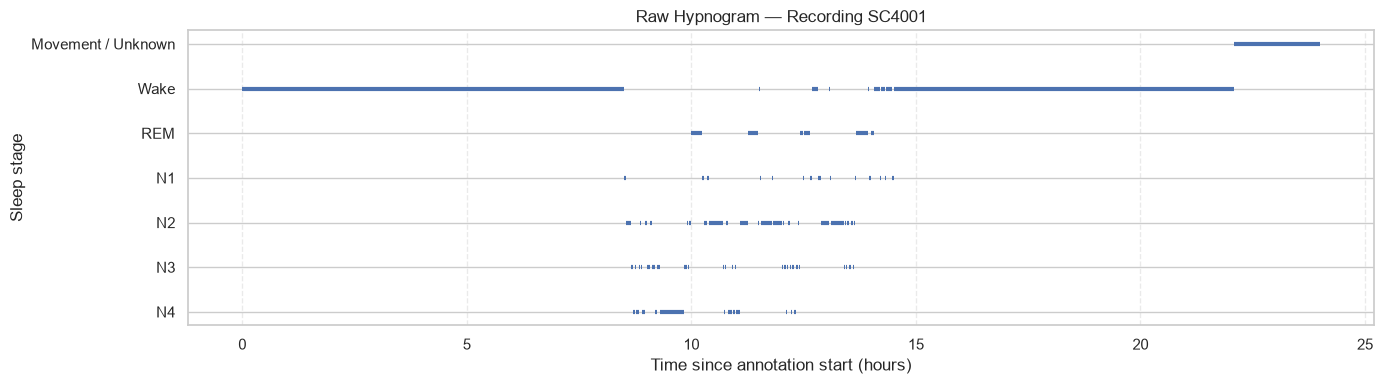

In [36]:

import matplotlib.pyplot as plt

# Map raw sleep-stage annotations to y-axis positions
stage_order = {
    "Sleep stage W": 4,
    "Sleep stage R": 3,
    "Sleep stage 1": 2,
    "Sleep stage 2": 1,
    "Sleep stage 3": 0,
    "Sleep stage 4": -1,
    "Movement time": 5,
    "Sleep stage ?": 5
}

# Create the plot
fig, ax = plt.subplots(figsize=(14, 4))

# Plot each annotation as a horizontal line
for onset, duration, description in zip(
    ann0.onset,
    ann0.duration,
    ann0.description
):
    stage = stage_order.get(description, 5)

    ax.hlines(
        y=stage,
        xmin=onset / 3600,
        xmax=(onset + duration) / 3600,
        linewidth=3
    )

# Configure the y-axis
ax.set_yticks([-1, 0, 1, 2, 3, 4, 5])
ax.set_yticklabels(["N4", "N3", "N2", "N1", "REM", "Wake", "Movement / Unknown"])

# Configure the plot
ax.set_xlabel("Time since annotation start (hours)")
ax.set_ylabel("Sleep stage")
ax.set_title(f"Raw Hypnogram — Recording {r0.recording_id}")

ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [38]:
r0 = recordings.iloc[0]
raw0 = mne.io.read_raw_edf(r0.psg, preload=False)
print("Channels:", raw0.ch_names)
print("Sampling rate (Hz):", raw0.info["sfreq"])
print(f"Duration: {raw0.times[-1]/3600:.1f} h")
CFG = {
    "channels": ["EEG Fpz-Cz"]
}
assert CFG["channels"][0] in raw0.ch_names, "Channel in CFG not found - update CFG['channels']"

ann0 = mne.read_annotations(r0.hyp)
print("\nHypnogram annotation labels:", sorted(set(ann0.description)))
print(pd.Series(ann0.description).value_counts())

Channels: ['EEG Fpz-Cz', 'EEG Pz-Oz', 'EOG horizontal', 'Resp oro-nasal', 'EMG submental', 'Temp rectal', 'Event marker']
Sampling rate (Hz): 100.0
Duration: 22.1 h

Hypnogram annotation labels: ['Sleep stage 1', 'Sleep stage 2', 'Sleep stage 3', 'Sleep stage 4', 'Sleep stage ?', 'Sleep stage R', 'Sleep stage W']
Sleep stage 3    48
Sleep stage 2    40
Sleep stage 1    24
Sleep stage 4    23
Sleep stage W    12
Sleep stage R     6
Sleep stage ?     1
Name: count, dtype: int64


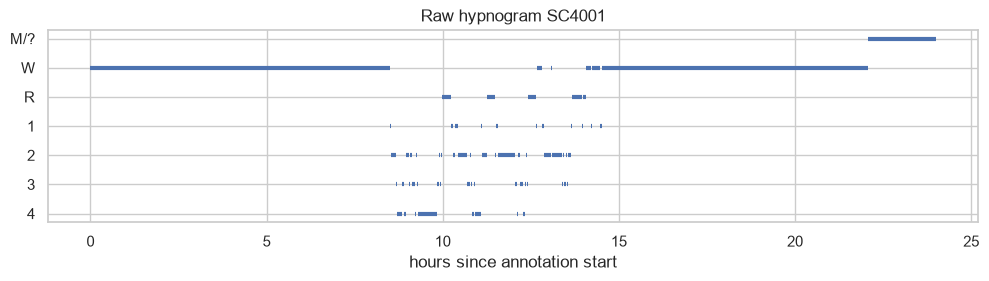

In [39]:
# Quick look at one hypnogram (raw annotation, before mapping)
order = {"Sleep stage W": 4, "Sleep stage R": 3, "Sleep stage 1": 2, "Sleep stage 2": 1,
         "Sleep stage 3": 0, "Sleep stage 4": -1, "Movement time": 5, "Sleep stage ?": 5}
fig, ax = plt.subplots(figsize=(12, 2.5))
for o, d, desc in zip(ann0.onset, ann0.duration, ann0.description):
    ax.hlines(order.get(desc, 5), o / 3600, (o + d) / 3600, lw=3)
ax.set_yticks([-1, 0, 1, 2, 3, 4, 5]); ax.set_yticklabels(["4", "3", "2", "1", "R", "W", "M/?"])
ax.set_xlabel("hours since annotation start"); ax.set_title(f"Raw hypnogram {r0.recording_id}")
plt.show()

## 5. Build the epoch-level feature table
Per recording: read PSG → resample (if needed) → band-pass → 30 s epochs → 16 features → labels.
Movement-time and unscored epochs get label `-1` and are dropped. Results are cached to disk so reruns are fast.

In [41]:
from pathlib import Path

print("Current directory:", Path.cwd())
print("Module exists:", Path("sleep_well.py").exists())

Current directory: c:\Users\TANVI\Downloads\ML project
Module exists: False


In [53]:

CFG.update({
    "bands_hz": {
        "delta": (0.5, 4.0),
        "theta": (4.0, 8.0),
        "alpha": (8.0, 13.0),
        "sigma": (12.0, 16.0),
        "beta": (13.0, 30.0)
    },
    "total_power_range_hz": (0.5, 40.0)
})

print("EEG frequency bands configured:")
for band, limits in CFG["bands_hz"].items():
    print(f"{band}: {limits[0]}–{limits[1]} Hz")


EEG frequency bands configured:
delta: 0.5–4.0 Hz
theta: 4.0–8.0 Hz
alpha: 8.0–13.0 Hz
sigma: 12.0–16.0 Hz
beta: 13.0–30.0 Hz


In [54]:
import importlib, slumberwell_core as sw
def build_feature_table(recordings, cfg):
    tables, log = [], []
    for _, r in recordings.iterrows():
        cache = CACHE_DIR / f"{r.recording_id}_{'-'.join(c.replace(' ', '') for c in cfg['channels'])}.csv"
        t0 = time.time()
        if cache.exists():
            df = pd.read_csv(cache)
        else:
            df = sw.featurize_recording(r.psg, r.hyp, cfg, subject_id=r.subject, recording_id=r.recording_id)
            df.to_csv(cache, index=False)
        tables.append(df)
        log.append((r.recording_id, len(df), round(time.time() - t0, 1)))
    return pd.concat(tables, ignore_index=True), pd.DataFrame(log, columns=["recording", "epochs", "sec"])

full_df, build_log = build_feature_table(recordings, CFG)
print(f"All epochs (before exclusions): {len(full_df):,}")
build_log.tail()

c:\Users\TANVI\Downloads\ML project\slumberwell_core.py:77: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(str(path), preload=False, verbose=verbose)
c:\Users\TANVI\Downloads\ML project\slumberwell_core.py:77: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(str(path), preload=False, verbose=verbose)
c:\Users\TANVI\Downloads\ML project\slumberwell_core.py:77: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(str(path), preload=False, verbose=verbose)
c:\Users\TANVI\Downloads\ML project\slumberwell_core.py:77: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(str(path), preload=False, verbose=verbose)
c:\Users\TANVI\Downloads\ML project\slumberwell_core

All epochs (before exclusions): 16,692


,recording,epochs,sec
1,SC4002,2830,1.5
2,SC4011,2802,1.4
3,SC4012,2850,1.3
4,SC4021,2804,1.3
5,SC4022,2756,1.2


In [55]:
FEATURES = sw.feature_names(CFG)
META = ["subject_id", "recording_id", "epoch_index", "label"]
print(len(FEATURES), "features:", FEATURES)

# Excluded: movement time / unscored / uncovered epochs (label == -1)
df = full_df[full_df["label"] >= 0].copy()
print(f"Dropped {len(full_df) - len(df):,} movement/unscored epochs -> {len(df):,} labelled epochs")

# Step 7 - trim long wake (per recording, on the epoch timeline)
if TRIM_WAKE:
    margin = int(WAKE_MARGIN_MIN * 60 / CFG["epoch_length_sec"])
    parts = []
    for rid, g in full_df.groupby("recording_id"):
        keep = sw.trim_wake_mask(g["label"].to_numpy(), margin)
        g = g[keep]
        parts.append(g[g["label"] >= 0])
    df = pd.concat(parts, ignore_index=True)
    print(f"After wake trimming (+/-{WAKE_MARGIN_MIN} min): {len(df):,} epochs")

16 features: ['mean', 'std', 'var', 'rms', 'min', 'max', 'range', 'delta_power', 'theta_power', 'alpha_power', 'beta_power', 'rel_delta', 'rel_theta', 'rel_alpha', 'rel_beta', 'spectral_entropy']
Dropped 4 movement/unscored epochs -> 16,688 labelled epochs
After wake trimming (+/-30 min): 6,291 epochs


## 6. Exploratory analysis
Class imbalance drives the metric choice (macro F1), class weighting and the N1 recall diagnostic (spec §4.5).

,epochs,percent
label,,
W,943,15.0
N1,596,9.5
N2,2792,44.4
N3,932,14.8
REM,1028,16.3


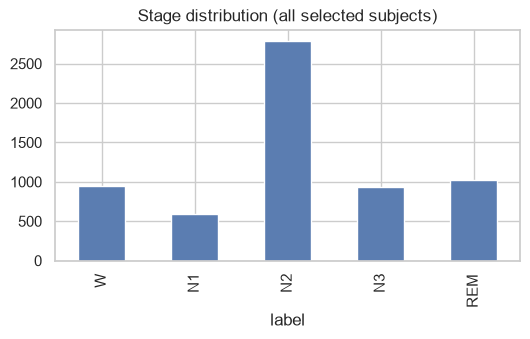

In [56]:
counts = df["label"].map(sw.INT_TO_LABEL).value_counts().reindex(sw.STAGE_NAMES)
summary = pd.DataFrame({"epochs": counts, "percent": (100 * counts / counts.sum()).round(1)})
display(summary)
ax = counts.plot(kind="bar", figsize=(6, 3), color="#5b7db1"); ax.set_title("Stage distribution (all selected subjects)")
plt.show()

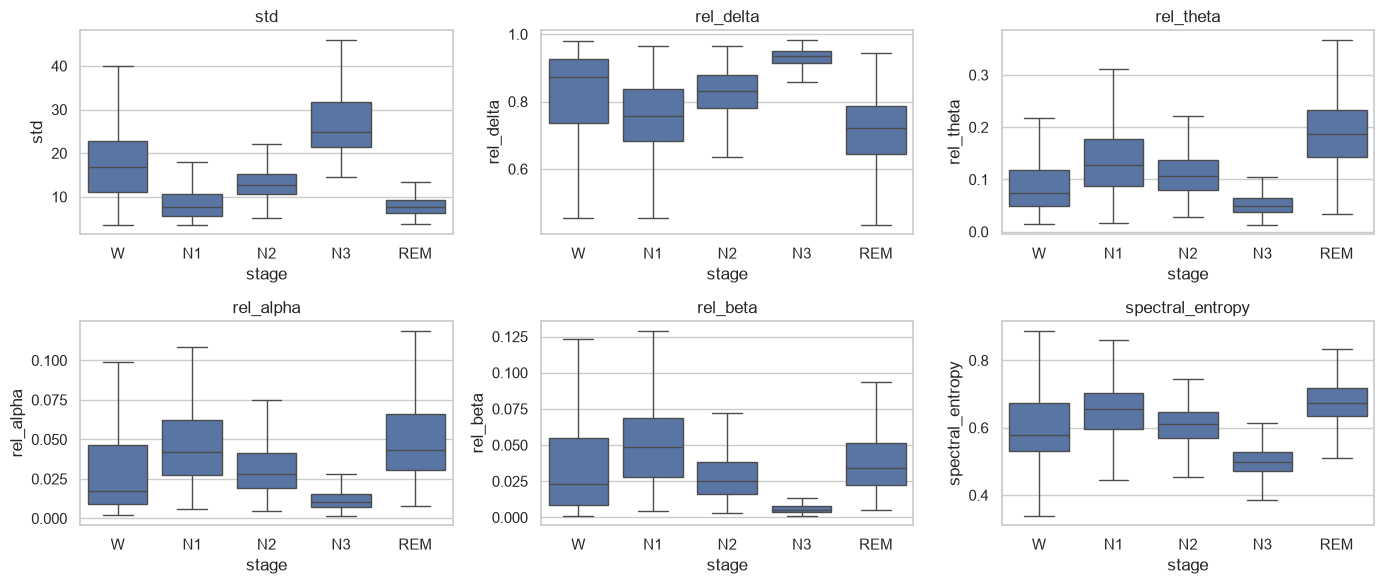

In [57]:
plot_df = df.copy(); plot_df["stage"] = plot_df["label"].map(sw.INT_TO_LABEL)
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for ax, feat in zip(axes.ravel(), ["std", "rel_delta", "rel_theta", "rel_alpha", "rel_beta", "spectral_entropy"]):
    sns.boxplot(data=plot_df, x="stage", y=feat, order=sw.STAGE_NAMES, showfliers=False, ax=ax)
    ax.set_title(feat)
plt.tight_layout(); plt.show()

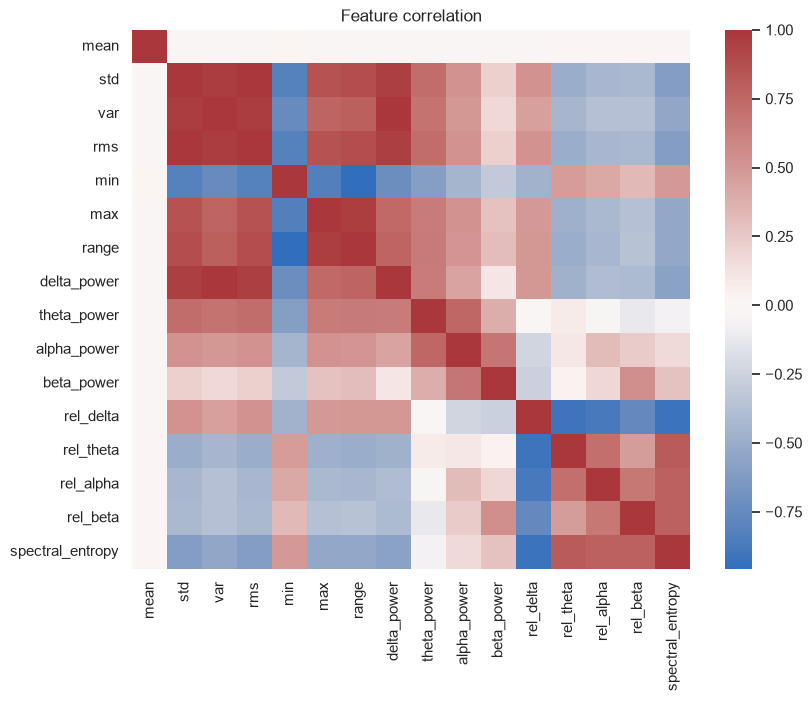

In [58]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df[FEATURES].corr(), cmap="vlag", center=0, ax=ax); ax.set_title("Feature correlation")
plt.show()

### 6b. Signal-level EDA
What the raw EEG and its spectrum look like per stage, and how much data each subject contributes.

c:\Users\TANVI\Downloads\ML project\slumberwell_core.py:77: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(str(path), preload=False, verbose=verbose)
c:\Users\TANVI\Downloads\ML project\slumberwell_core.py:77: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(str(path), preload=False, verbose=verbose)
c:\Users\TANVI\Downloads\ML project\slumberwell_core.py:77: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(str(path), preload=False, verbose=verbose)


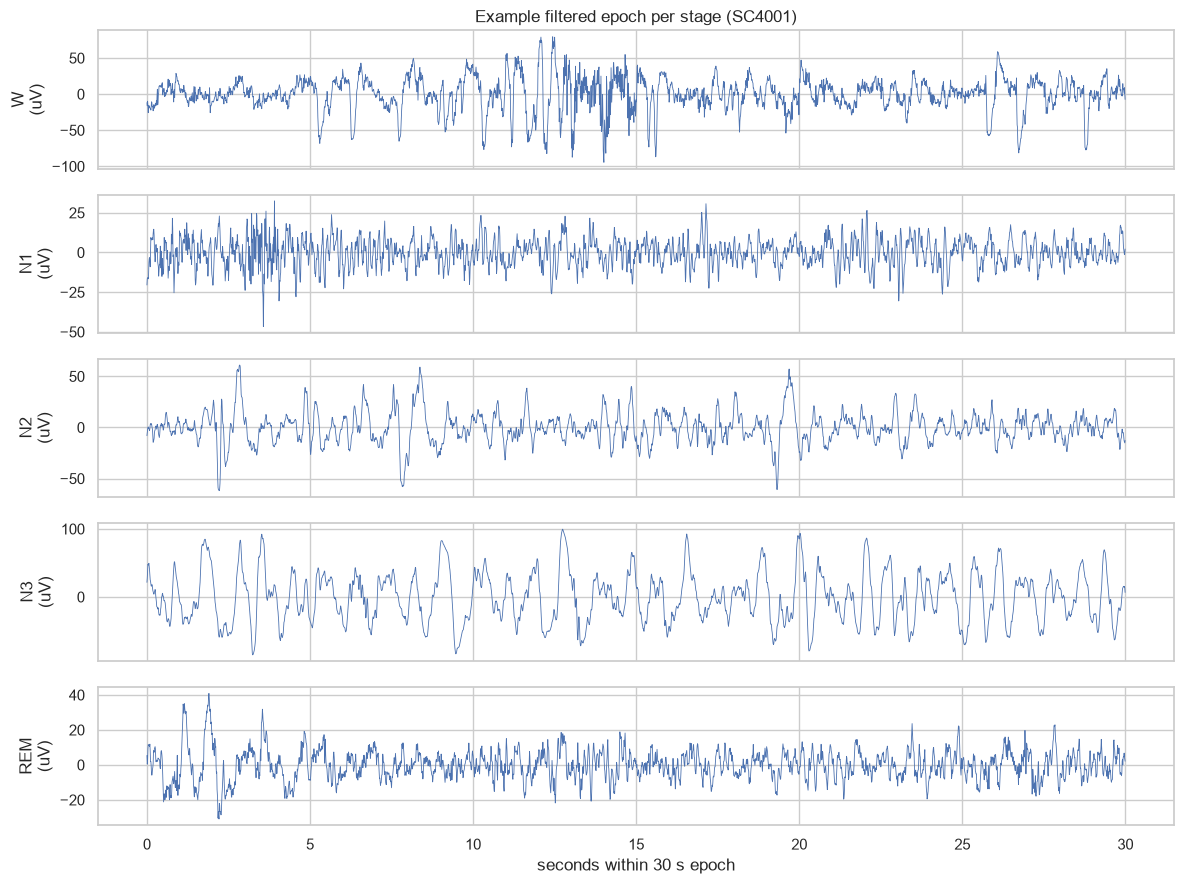

In [59]:
r0 = recordings.iloc[0]
ep0, raw_r0 = sw.preprocess_signal(r0.psg, CFG)
on, du, de = sw.read_hypnogram(r0.hyp, raw_r0)
lab0 = sw.epoch_labels_from_annotations(on, du, de, len(ep0), CFG["epoch_length_sec"])
fs = CFG["sampling_rate_hz"]; t = np.arange(ep0.shape[-1]) / fs

fig, axes = plt.subplots(5, 1, figsize=(12, 9), sharex=True)
for ax, s in zip(axes, sw.STAGE_NAMES):
    idx = np.where(lab0 == sw.LABEL_TO_INT[s])[0]
    if len(idx):
        ax.plot(t, ep0[idx[len(idx) // 2], 0], lw=.6)
    ax.set_ylabel(f"{s}\n(uV)")
axes[-1].set_xlabel("seconds within 30 s epoch"); axes[0].set_title(f"Example filtered epoch per stage ({r0.recording_id})")
plt.tight_layout(); plt.show()

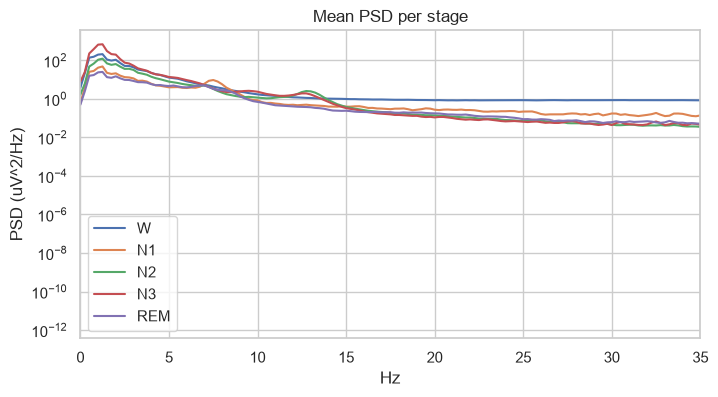

In [60]:
from scipy.signal import welch
fig, ax = plt.subplots(figsize=(8, 4))
for s in sw.STAGE_NAMES:
    idx = np.where(lab0 == sw.LABEL_TO_INT[s])[0]
    if len(idx):
        f, p = welch(ep0[idx, 0], fs=fs, nperseg=400, noverlap=200, axis=-1)
        ax.semilogy(f, p.mean(axis=0), label=s)
ax.set_xlim(0, 35); ax.set_xlabel("Hz"); ax.set_ylabel("PSD (uV^2/Hz)"); ax.legend(); ax.set_title("Mean PSD per stage")
plt.show()

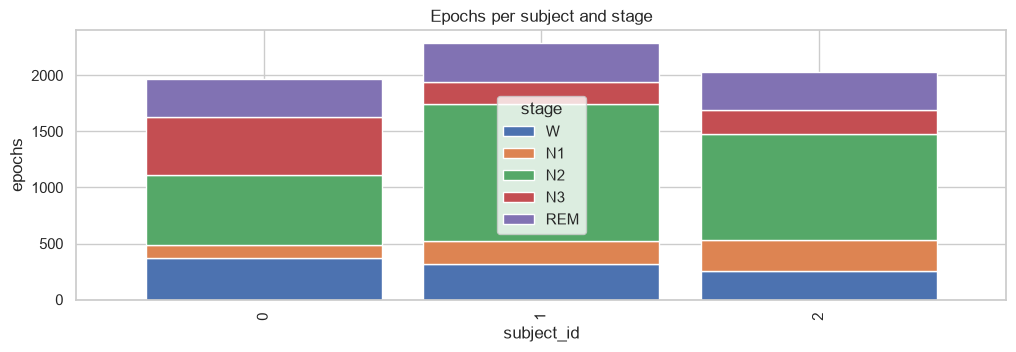

Saved cleaned dataset: cache\clean_epoch_features.csv


In [61]:
per_subj = df.assign(stage=df["label"].map(sw.INT_TO_LABEL)).groupby(["subject_id", "stage"]).size().unstack(fill_value=0)[sw.STAGE_NAMES]
per_subj.plot(kind="bar", stacked=True, figsize=(12, 3.5), width=.85); plt.title("Epochs per subject and stage"); plt.ylabel("epochs")
plt.show()
df.to_csv(CACHE_DIR / "clean_epoch_features.csv", index=False)       # cleaned, labelled dataset
print("Saved cleaned dataset:", CACHE_DIR / "clean_epoch_features.csv")

## 7. Subject-wise split (70 / 15 / 15)
The split is made on **subject IDs**, so both nights of a subject land in one partition. The mapping is saved and reused by every model.

In [62]:
subjects = np.array(sorted(df["subject_id"].unique()))
rng = np.random.RandomState(SEED); rng.shuffle(subjects)
n = len(subjects)
n_test = max(1, round(0.15 * n)); n_val = max(1, round(0.15 * n))
test_s, val_s, train_s = subjects[:n_test], subjects[n_test:n_test + n_val], subjects[n_test + n_val:]

split = {"seed": SEED, "train": sorted(map(int, train_s)), "val": sorted(map(int, val_s)), "test": sorted(map(int, test_s))}
json.dump(split, open(ARTIFACT_DIR / "subject_split.json", "w"), indent=2)
assert not (set(train_s) & set(val_s)) and not (set(train_s) & set(test_s)) and not (set(val_s) & set(test_s))
print({k: len(v) for k, v in split.items() if k != "seed"}, "subjects")

part = lambda ids: df[df["subject_id"].isin(ids)].reset_index(drop=True)
train_df, val_df, test_df = part(train_s), part(val_s), part(test_s)
print({k: len(d) for k, d in zip(["train", "val", "test"], [train_df, val_df, test_df])}, "epochs")

{'train': 1, 'val': 1, 'test': 1} subjects
{'train': 2034, 'val': 2289, 'test': 1968} epochs


## 8. Quality screening (training-derived thresholds)
Flat epochs (almost no signal) and extreme-amplitude epochs are dropped. The upper amplitude threshold is the 99.9th percentile
of `max |amplitude|` in the **training** partition only, then applied to all partitions.

In [64]:

# Initialize quality settings if they do not exist
CFG.setdefault("quality", {})

# Minimum standard deviation threshold (in microvolts)
CFG["quality"].setdefault("flat_std_uv", 1.0)

# Maximum absolute amplitude threshold (in microvolts)
# This will be estimated from the training data below.
CFG["quality"].setdefault("max_abs_uv", None)

print("Quality configuration:")
print(CFG["quality"])


Quality configuration:
{'flat_std_uv': 1.0, 'max_abs_uv': None}


In [65]:
if APPLY_QUALITY:
    abs_peak = lambda d: np.maximum(d["max"].abs(), d["min"].abs())
    CFG["quality"]["max_abs_uv"] = float(np.quantile(abs_peak(train_df), 0.999))
    flat_thr, max_thr = CFG["quality"]["flat_std_uv"], CFG["quality"]["max_abs_uv"]
    def screen(d):
        ok = (d["std"] > flat_thr) & (abs_peak(d) <= max_thr)
        return d[ok].reset_index(drop=True)
    before = (len(train_df), len(val_df), len(test_df))
    train_df, val_df, test_df = screen(train_df), screen(val_df), screen(test_df)
    print(f"flat std < {flat_thr} uV or |amp| > {max_thr:.0f} uV removed:",
          [b - len(d) for b, d in zip(before, (train_df, val_df, test_df))], "(train, val, test)")

X_train, y_train = train_df[FEATURES].to_numpy(), train_df["label"].to_numpy()
X_val,   y_val   = val_df[FEATURES].to_numpy(),   val_df["label"].to_numpy()
X_test,  y_test  = test_df[FEATURES].to_numpy(),  test_df["label"].to_numpy()
groups_train = train_df["subject_id"].to_numpy()
print(X_train.shape, X_val.shape, X_test.shape)

flat std < 1.0 uV or |amp| > 143 uV removed: [3, 19, 4] (train, val, test)
(2031, 16) (2270, 16) (1964, 16)


## 9. Candidate models and evaluation helpers
Tree models need no scaling. The SVM is wrapped in a pipeline so the scaler is fitted on training data only.
XGBoost and HistGradientBoosting get balanced per-sample weights; labels are already integers 0..4.

In [66]:
def make_model(name, **p):
    if name == "Random Forest":
        return RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=SEED, **p)
    if name == "Extra Trees":
        return ExtraTreesClassifier(class_weight="balanced", n_jobs=-1, random_state=SEED, **p)
    if name == "XGBoost":
        return XGBClassifier(objective="multi:softprob", tree_method="hist", n_jobs=-1, random_state=SEED, **p)
    if name == "SVM":
        return make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced", probability=False,
                                                   random_state=SEED, **p))
    if name == "HistGradientBoosting":
        return HistGradientBoostingClassifier(random_state=SEED, **p)
    if name == "Majority baseline":
        return DummyClassifier(strategy="most_frequent")
    raise ValueError(name)

def fit_model(name, model, X, y):
    if name == "SVM" and len(X) > SVM_MAX_TRAIN:                      # random subsample for SVM only
        idx = np.random.RandomState(SEED).choice(len(X), SVM_MAX_TRAIN, replace=False)
        X, y = X[idx], y[idx]
    if name in ("XGBoost", "HistGradientBoosting"):
        model.fit(X, y, sample_weight=compute_sample_weight("balanced", y))
    else:
        model.fit(X, y)
    return model

LABELS = list(range(5))
def evaluate(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, zero_division=0)
    return {
        "macro_f1": f1_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0),
        "accuracy": accuracy_score(y_true, y_pred),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", labels=LABELS, zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0),
        "n1_recall": r[sw.LABEL_TO_INT["N1"]],
        "per_class": {s: {"precision": p[i], "recall": r[i], "f1": f[i]} for i, s in enumerate(sw.STAGE_NAMES)},
    }

## 10. Compare all candidates with default settings (train → validation)

In [67]:
DEFAULTS = {
    "Majority baseline": {},
    "Random Forest": {"n_estimators": 200},
    "Extra Trees": {"n_estimators": 200},
    "XGBoost": {"n_estimators": 200, "max_depth": 5, "learning_rate": 0.1},
    "SVM": {},
    "HistGradientBoosting": {},
}
rows, fitted = [], {}
for name, params in DEFAULTS.items():
    t0 = time.time(); m = fit_model(name, make_model(name, **params), X_train, y_train); t_fit = time.time() - t0
    t0 = time.time(); pred = m.predict(X_val); t_pred = time.time() - t0
    ev = evaluate(y_val, pred); fitted[name] = m
    rows.append({"model": name, **{k: ev[k] for k in ["macro_f1", "accuracy", "weighted_f1", "macro_recall", "n1_recall"]},
                 "train_sec": t_fit, "predict_sec": t_pred})
default_results = pd.DataFrame(rows).sort_values("macro_f1", ascending=False).reset_index(drop=True)
default_results.round(4)

,model,macro_f1,accuracy,weighted_f1,macro_recall,n1_recall,train_sec,predict_sec
0,Random Forest,0.6749,0.7211,0.7372,0.6841,0.5373,0.6268,0.0780
1,Extra Trees,0.6735,0.7784,0.7631,0.6439,0.3483,0.4261,0.0995
2,HistGradientBoosting,0.6538,0.7330,0.7332,0.6347,0.3930,3.9717,0.0442
3,XGBoost,0.6456,0.7004,0.7136,0.6401,0.4179,1.1152,0.0099
4,SVM,0.6116,0.6216,0.6506,0.6600,0.4925,0.1615,0.3649
5,Majority baseline,0.1400,0.5383,0.3768,0.2000,0.0000,0.0364,0.0000


## 11. Tune the strongest candidates (spec §7.4 search spaces)
Random Forest and XGBoost are always tuned; the top-`TUNE_TOP_K` default models are added. Each trial is trained on the training
subjects and scored on validation **macro F1**. The search is a seeded random sample of the grid (`N_TUNING_TRIALS`).

In [68]:
from sklearn.model_selection import ParameterSampler
GRIDS = {
    "Random Forest": {"n_estimators": [200, 400], "max_depth": [None, 20, 40],
                      "min_samples_leaf": [1, 2, 4], "max_features": ["sqrt", 0.7]},
    "Extra Trees":   {"n_estimators": [200, 400], "max_depth": [None, 20, 40],
                      "min_samples_leaf": [1, 2, 4], "max_features": ["sqrt", 0.7]},
    "XGBoost":       {"n_estimators": [200, 400], "max_depth": [3, 5, 7],
                      "learning_rate": [0.03, 0.1], "subsample": [0.8, 1.0]},
    "SVM":           {"svc__C": [0.1, 1, 10], "svc__gamma": ["scale", 0.01]},
    "HistGradientBoosting": {"learning_rate": [0.05, 0.1], "max_depth": [None, 6], "max_iter": [200, 400]},
}
cands = set(["Random Forest", "XGBoost"]) | set(
    m for m in default_results["model"].head(TUNE_TOP_K + 1) if m in GRIDS)
print("Tuning:", sorted(cands))

def build_tuned(name, params):
    if name == "SVM":
        return make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced", random_state=SEED,
                                                   C=params["svc__C"], gamma=params["svc__gamma"]))
    return make_model(name, **params)

trials = []
for name in sorted(cands):
    sampler = ParameterSampler(GRIDS[name], n_iter=min(N_TUNING_TRIALS, np.prod([len(v) for v in GRIDS[name].values()])),
                               random_state=SEED)
    for params in sampler:
        t0 = time.time(); m = fit_model(name, build_tuned(name, params), X_train, y_train); t_fit = time.time() - t0
        t0 = time.time(); pred = m.predict(X_val); t_pred = time.time() - t0
        ev = evaluate(y_val, pred)
        trials.append({"model": name, "params": params, "macro_f1": ev["macro_f1"], "n1_recall": ev["n1_recall"],
                       "accuracy": ev["accuracy"], "train_sec": t_fit, "predict_sec": t_pred})
        print(f"{name:22s} macro_f1={ev['macro_f1']:.4f}  {params}")
tuning = pd.DataFrame(trials).sort_values("macro_f1", ascending=False).reset_index(drop=True)

Tuning: ['Extra Trees', 'HistGradientBoosting', 'Random Forest', 'XGBoost']
Extra Trees            macro_f1=0.7017  {'n_estimators': 400, 'min_samples_leaf': 4, 'max_features': 0.7, 'max_depth': 40}
Extra Trees            macro_f1=0.6770  {'n_estimators': 400, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 20}
Extra Trees            macro_f1=0.6912  {'n_estimators': 200, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 40}
Extra Trees            macro_f1=0.6789  {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 0.7, 'max_depth': 40}
Extra Trees            macro_f1=0.7038  {'n_estimators': 200, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 20}
Extra Trees            macro_f1=0.6713  {'n_estimators': 400, 'min_samples_leaf': 1, 'max_features': 0.7, 'max_depth': 40}
Extra Trees            macro_f1=0.6870  {'n_estimators': 400, 'min_samples_leaf': 2, 'max_features': 0.7, 'max_depth': 20}
Extra Trees            macro_f1=0.6803  {'n_estimators

## 12. Select the final model
Highest validation macro F1; ties (within 0.001) broken by N1 recall, then runtime (spec §7.5 step 3).

In [69]:
pool = tuning.copy()
# include the untuned defaults so a default can win if tuning did not help
for _, r in default_results.iterrows():
    if r["model"] in cands:
        pool = pd.concat([pool, pd.DataFrame([{"model": r["model"], "params": DEFAULTS[r["model"]], "macro_f1": r["macro_f1"],
                          "n1_recall": r["n1_recall"], "accuracy": r["accuracy"], "train_sec": r["train_sec"],
                          "predict_sec": r["predict_sec"]}])], ignore_index=True)
pool["f1_bin"] = (pool["macro_f1"] / 0.001).round()
pool = pool.sort_values(["f1_bin", "n1_recall", "predict_sec"], ascending=[False, False, True]).reset_index(drop=True)
best = pool.iloc[0]
BEST_NAME, BEST_PARAMS = best["model"], best["params"]
print(f"Selected: {BEST_NAME}  validation macro F1 = {best['macro_f1']:.4f}\nParams: {BEST_PARAMS}")
pool.drop(columns="f1_bin").head(10).round(4)

Selected: Extra Trees  validation macro F1 = 0.7038
Params: {'n_estimators': 200, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 20}


,model,params,macro_f1,n1_recall,accuracy,train_sec,predict_sec
0,Extra Trees,"{'n_estimators': 200, 'min_samples_leaf': 4, '...",0.7038,0.4577,0.7841,0.4285,0.0881
1,Extra Trees,"{'n_estimators': 400, 'min_samples_leaf': 4, '...",0.7017,0.5025,0.7775,0.9733,0.4942
2,Extra Trees,"{'n_estimators': 200, 'min_samples_leaf': 2, '...",0.6912,0.4179,0.7841,0.4782,0.0997
3,Extra Trees,"{'n_estimators': 400, 'min_samples_leaf': 2, '...",0.6870,0.4328,0.7744,0.9199,0.1768
4,Random Forest,"{'n_estimators': 200, 'min_samples_leaf': 4, '...",0.6812,0.5373,0.7339,0.6227,0.0898
5,XGBoost,"{'subsample': 0.8, 'n_estimators': 200, 'max_d...",0.6795,0.4925,0.7335,0.5976,0.0050
6,Extra Trees,"{'n_estimators': 200, 'min_samples_leaf': 1, '...",0.6803,0.3333,0.7833,0.4798,0.0987
7,Extra Trees,"{'n_estimators': 200, 'min_samples_leaf': 1, '...",0.6789,0.3831,0.7696,0.4604,0.0908
8,Extra Trees,"{'n_estimators': 400, 'min_samples_leaf': 1, '...",0.6770,0.3333,0.7819,0.9005,0.1871
9,Random Forest,{'n_estimators': 200},0.6749,0.5373,0.7211,0.6268,0.0780


## 12b. Model analysis table
One row per model: default vs best-tuned validation scores, runtime, chosen hyperparameters, and which one was selected. Saved to `artifacts/model_comparison.csv`.

,default_macro_f1,default_accuracy,default_n1_recall,default_train_sec,default_predict_sec,tuned_macro_f1,tuned_accuracy,tuned_n1_recall,tuned_train_sec,best_params,val_macro_f1_final,selected
model,,,,,,,,,,,,
Extra Trees,0.6735,0.7784,0.3483,0.4261,0.0995,0.7038,0.7841,0.4577,0.4285,"{'n_estimators': 200, 'min_samples_leaf': 4, '...",0.7038,True
Random Forest,0.6749,0.7211,0.5373,0.6268,0.0780,0.6812,0.7339,0.5373,0.6227,"{'n_estimators': 200, 'min_samples_leaf': 4, '...",0.6812,False
XGBoost,0.6456,0.7004,0.4179,1.1152,0.0099,0.6795,0.7335,0.4925,0.5976,"{'subsample': 0.8, 'n_estimators': 200, 'max_d...",0.6795,False
HistGradientBoosting,0.6538,0.7330,0.3930,3.9717,0.0442,0.6635,0.7414,0.4080,5.8912,"{'max_iter': 200, 'max_depth': None, 'learning...",0.6635,False
SVM,0.6116,0.6216,0.4925,0.1615,0.3649,NaN,NaN,NaN,NaN,NaN,0.6116,False
Majority baseline,0.1400,0.5383,0.0000,0.0364,0.0000,NaN,NaN,NaN,NaN,NaN,0.1400,False


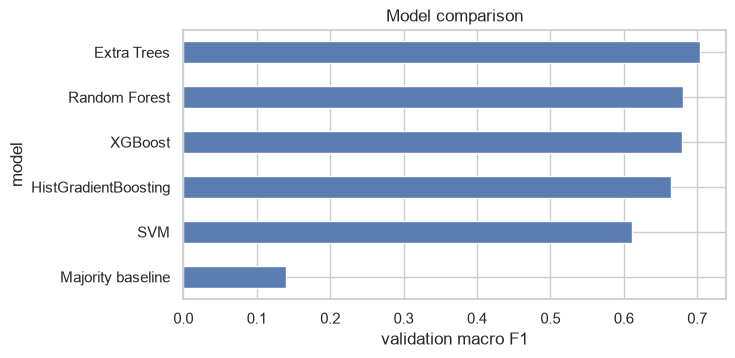

In [70]:
best_tuned = tuning.sort_values("macro_f1", ascending=False).groupby("model").head(1).set_index("model")
analysis = default_results.set_index("model")[["macro_f1", "accuracy", "n1_recall", "train_sec", "predict_sec"]].add_prefix("default_")
analysis["tuned_macro_f1"] = best_tuned["macro_f1"]
analysis["tuned_accuracy"] = best_tuned["accuracy"]
analysis["tuned_n1_recall"] = best_tuned["n1_recall"]
analysis["tuned_train_sec"] = best_tuned["train_sec"]
analysis["best_params"] = best_tuned["params"].astype(str)
analysis["val_macro_f1_final"] = analysis[["default_macro_f1", "tuned_macro_f1"]].max(axis=1)
analysis["selected"] = analysis.index == BEST_NAME
analysis = analysis.sort_values("val_macro_f1_final", ascending=False)
analysis.to_csv(ARTIFACT_DIR / "model_comparison.csv")
display(analysis.round(4))

ax = analysis["val_macro_f1_final"].plot(kind="barh", figsize=(7, 3.5), color="#5b7db1")
ax.invert_yaxis(); ax.set_xlabel("validation macro F1"); ax.set_title("Model comparison"); plt.show()

## 13. Final fit and one-shot test evaluation
Optionally refit on train + validation subjects with the chosen hyperparameters, then evaluate on the held-out **test** subjects **once**.
No choices are made from test results.

In [71]:
if REFIT_TRAIN_VAL:
    X_fit, y_fit = np.vstack([X_train, X_val]), np.concatenate([y_train, y_val])
else:
    X_fit, y_fit = X_train, y_train
final_model = fit_model(BEST_NAME, build_tuned(BEST_NAME, BEST_PARAMS), X_fit, y_fit)

t0 = time.time(); pred_test = final_model.predict(X_test); t_pred = time.time() - t0
test_eval = evaluate(y_test, pred_test)
print(f"TEST  macro F1 = {test_eval['macro_f1']:.4f} | accuracy = {test_eval['accuracy']:.4f} | "
      f"weighted F1 = {test_eval['weighted_f1']:.4f} | macro recall = {test_eval['macro_recall']:.4f} | "
      f"N1 recall = {test_eval['n1_recall']:.4f}")
print(f"Inference: {1000 * t_pred / len(X_test):.3f} ms/epoch")
print(classification_report(y_test, pred_test, labels=LABELS, target_names=sw.STAGE_NAMES, zero_division=0, digits=3))

TEST  macro F1 = 0.3077 | accuracy = 0.4206 | weighted F1 = 0.3791 | macro recall = 0.3215 | N1 recall = 0.0345
Inference: 0.044 ms/epoch
              precision    recall  f1-score   support

           W      0.198     0.322     0.245       369
          N1      0.500     0.034     0.065       116
          N2      0.471     0.860     0.609       622
          N3      0.851     0.199     0.323       517
         REM      0.670     0.191     0.297       340

    accuracy                          0.421      1964
   macro avg      0.538     0.322     0.308      1964
weighted avg      0.556     0.421     0.379      1964



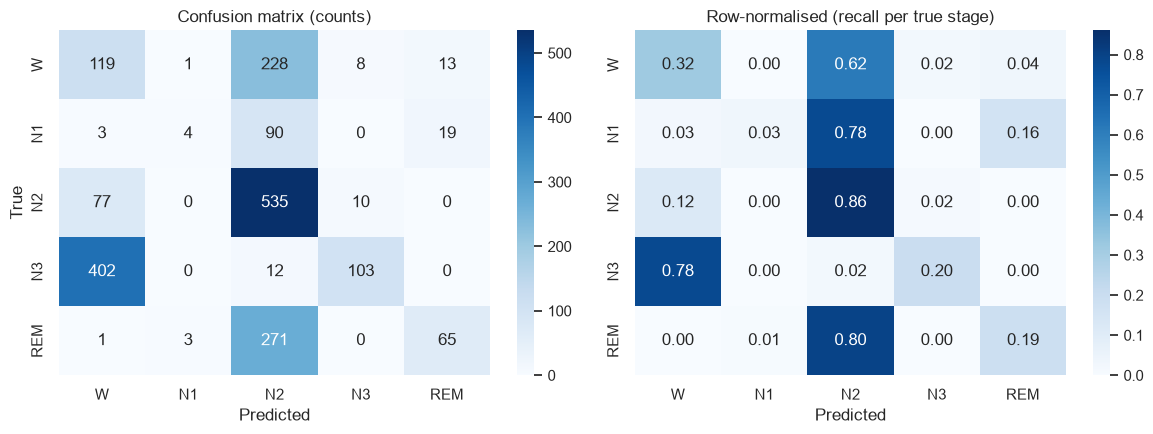

In [72]:
cm = confusion_matrix(y_test, pred_test, labels=LABELS)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=sw.STAGE_NAMES, yticklabels=sw.STAGE_NAMES, ax=axes[0])
axes[0].set_title("Confusion matrix (counts)"); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True")
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Blues",
            xticklabels=sw.STAGE_NAMES, yticklabels=sw.STAGE_NAMES, ax=axes[1])
axes[1].set_title("Row-normalised (recall per true stage)"); axes[1].set_xlabel("Predicted")
plt.tight_layout(); plt.show()

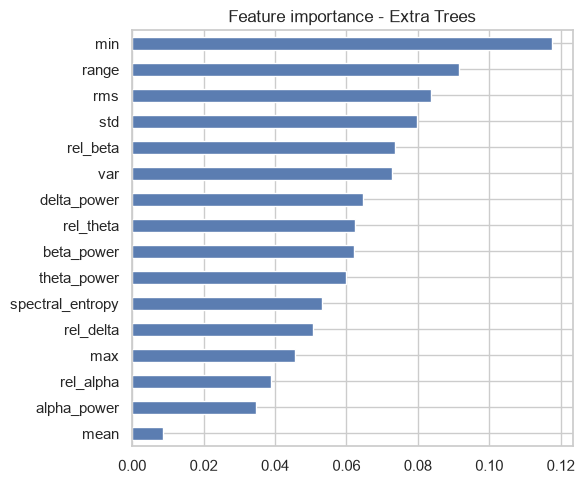

In [73]:
# Feature importance (tree models) or permutation importance on validation (SVM)
est = final_model
if hasattr(est, "feature_importances_"):
    imp = pd.Series(est.feature_importances_, index=FEATURES)
else:
    from sklearn.inspection import permutation_importance
    r = permutation_importance(est, X_val, y_val, scoring="f1_macro", n_repeats=3, random_state=SEED)
    imp = pd.Series(r.importances_mean, index=FEATURES)
imp.sort_values().plot(kind="barh", figsize=(6, 5), color="#5b7db1"); plt.title(f"Feature importance - {BEST_NAME}")
plt.tight_layout(); plt.show()

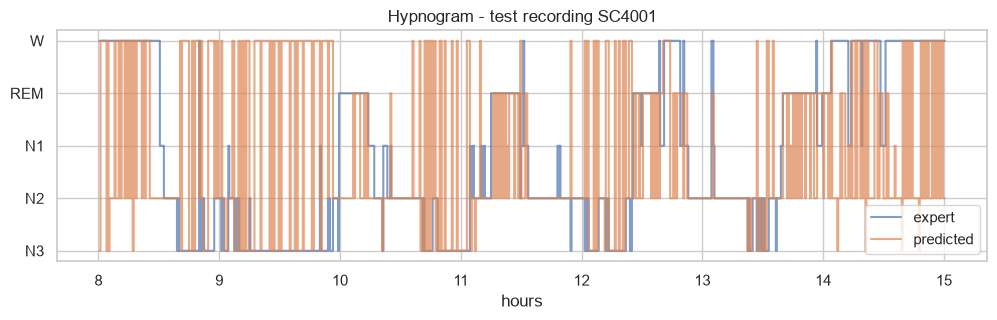

In [74]:
# Predicted vs true hypnogram for one test recording
rid = test_df["recording_id"].iloc[0]
g = test_df[test_df["recording_id"] == rid]
p = final_model.predict(g[FEATURES].to_numpy())
order = {0: 4, 4: 3, 1: 2, 2: 1, 3: 0}        # W, REM, N1, N2, N3 from top to bottom
fig, ax = plt.subplots(figsize=(12, 3))
ax.step(g["epoch_index"] * 0.5 / 60, [order[v] for v in g["label"]], where="post", label="expert", alpha=.7)
ax.step(g["epoch_index"] * 0.5 / 60, [order[v] for v in p], where="post", label="predicted", alpha=.7)
ax.set_yticks([0, 1, 2, 3, 4]); ax.set_yticklabels(["N3", "N2", "N1", "REM", "W"]); ax.set_xlabel("hours"); ax.legend()
ax.set_title(f"Hypnogram - test recording {rid}"); plt.show()

In [75]:
per_class = pd.DataFrame(test_eval["per_class"]).T.round(4)
per_class["support"] = np.bincount(y_test, minlength=5)
per_class.to_csv(ARTIFACT_DIR / "test_per_class_metrics.csv")
display(per_class)

,precision,recall,f1,support
W,0.1977,0.3225,0.2451,369
N1,0.5000,0.0345,0.0645,116
N2,0.4710,0.8601,0.6086,622
N3,0.8512,0.1992,0.3229,517
REM,0.6701,0.1912,0.2975,340


## 14. Save artifacts (spec §8)
Writes `best_model.joblib`, `feature_names.json`, `label_mapping.json`, `preprocessing_config.json`,
`evaluation_metrics.json`, plus the subject split and a `requirements.txt` with the library versions used.

In [76]:
joblib.dump(final_model, ARTIFACT_DIR / "best_model.joblib")
json.dump(FEATURES, open(ARTIFACT_DIR / "feature_names.json", "w"), indent=2)
json.dump(sw.INT_TO_LABEL, open(ARTIFACT_DIR / "label_mapping.json", "w"), indent=2)
json.dump(CFG, open(ARTIFACT_DIR / "preprocessing_config.json", "w"), indent=2)

def clean(o):
    if isinstance(o, dict):  return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.integer,)):  return int(o)
    return o

val_pred = final_model.predict(X_val)
versions = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scipy": scipy.__version__, "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__,
            "mne": mne.__version__, "joblib": joblib.__version__}
metrics = clean({
    "model_name": BEST_NAME, "hyperparameters": BEST_PARAMS, "refit_on_train_plus_val": REFIT_TRAIN_VAL,
    "validation": {"macro_f1_of_selection_run": best["macro_f1"]},
    "validation_final_model": evaluate(y_val, val_pred) if not REFIT_TRAIN_VAL else "not reported (val used in refit)",
    "test": {**test_eval, "confusion_matrix": cm.tolist(), "inference_ms_per_epoch": 1000 * t_pred / len(X_test)},
    "model_comparison_validation": default_results.to_dict("records"),
    "tuning_trials": tuning.to_dict("records"),
    "split": {"seed": SEED, "n_subjects": {k: len(v) for k, v in split.items() if k != "seed"},
              "n_epochs": {"train": len(train_df), "val": len(val_df), "test": len(test_df)}},
    "class_names": sw.STAGE_NAMES, "library_versions": versions,
})
json.dump(metrics, open(ARTIFACT_DIR / "evaluation_metrics.json", "w"), indent=2)
Path(ARTIFACT_DIR / "requirements.txt").write_text(
    "\n".join(f"{k}=={v}" for k, v in versions.items() if k != "python") + "\n")
print("Saved:", sorted(p.name for p in ARTIFACT_DIR.iterdir()))

Saved: ['best_model.joblib', 'evaluation_metrics.json', 'feature_names.json', 'label_mapping.json', 'model_comparison.csv', 'preprocessing_config.json', 'requirements.txt', 'subject_split.json', 'test_per_class_metrics.csv']


## 15. Inference sanity check (training/serving parity)
Reload the artifacts and run the **inference path** (`featurize_edf`: EDF only, no hypnogram) on a test-subject recording.
Features must match those used in training for the same epochs, and predictions must be reproducible. This is the same code path the FastAPI backend will use.

In [77]:
model = joblib.load(ARTIFACT_DIR / "best_model.joblib")
feat_names = json.load(open(ARTIFACT_DIR / "feature_names.json"))
cfg_loaded = json.load(open(ARTIFACT_DIR / "preprocessing_config.json"))
labmap = {int(k): v for k, v in json.load(open(ARTIFACT_DIR / "label_mapping.json")).items()}

test_rec = recordings[recordings["subject"].isin(split["test"])].iloc[0]
X_inf = sw.featurize_edf(test_rec.psg, cfg_loaded)[feat_names]
stages = [labmap[i] for i in model.predict(X_inf.to_numpy())]

# parity: inference features == training-table features for the same epochs
ref = full_df[full_df["recording_id"] == test_rec.recording_id].set_index("epoch_index")[feat_names]
common = ref.index.intersection(X_inf.index)
print("max |feature difference| vs training table:", float(np.abs(ref.loc[common].to_numpy() - X_inf.loc[common].to_numpy()).max()))

print(f"{test_rec.recording_id}: {len(stages)} epochs")
print(json.dumps(sw.summarize_predictions(stages), indent=2))

c:\Users\TANVI\Downloads\ML project\slumberwell_core.py:77: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(str(path), preload=False, verbose=verbose)
c:\Users\TANVI\Downloads\ML project\slumberwell_core.py:77: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(str(path), preload=False, verbose=verbose)
c:\Users\TANVI\Downloads\ML project\slumberwell_core.py:77: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(str(path), preload=False, verbose=verbose)


max |feature difference| vs training table: 0.0
SC4001: 2650 epochs
{
  "total_recording_min": 1325.0,
  "total_sleep_min": 798.0,
  "sleep_efficiency_pct": 60.22641509433962,
  "sleep_onset_latency_min": 0.5,
  "rem_latency_min": 606.0,
  "stage_counts": {
    "W": 1054,
    "N1": 8,
    "N2": 1374,
    "N3": 117,
    "REM": 97
  },
  "stage_percent": {
    "W": 39.77358490566038,
    "N1": 0.3018867924528302,
    "N2": 51.84905660377358,
    "N3": 4.415094339622642,
    "REM": 3.660377358490566
  }
}


## Notes and next steps
- **Staged scaling:** raise `N_SUBJECTS` (up to 78) once this runs end to end; `cache/` makes reruns cheap.
- **Ablations worth running** (spec §5 and §6): `TRIM_WAKE` on/off, add `"EEG Pz-Oz"` to `CFG["channels"]`, band ratios, Hjorth parameters, and neighbouring-epoch context features.
- **Report as-is:** the test numbers are one-shot; do not tune against them.
- **Handoff to Phase 2:** copy `slumberwell_core.py` and the `artifacts/` folder into the backend. Class probabilities from `predict_proba` are classifier scores, not calibrated clinical confidence.
- This is a research prototype, not a medical device.